# Machine Learning na prática: classificação e clustering

**Público:** iniciantes em Scikit-Learn, com conhecimentos básicos de Python  
**Duração sugerida:** 60 minutos  
**Bibliotecas:** Pandas, Matplotlib e Scikit-Learn

Nesta aula você será o desenvolvedor de dois pequenos sistemas:

1. **Classificação (aprendizado supervisionado):** prever se um aluno será **aprovado** ou **reprovado** a partir de exemplos fictícios.
2. **Clustering (aprendizado não supervisionado):** descobrir **grupos de clientes** que têm hábitos de compra semelhantes.

> **Importante:** todos os dados foram inventados para fins educacionais. As previsões de aprovação não devem ser usadas para decisões reais sobre estudantes, e os grupos de clientes não representam uma análise comercial validada.

### Roteiro de tempo

| Etapa | Tempo aproximado |
|---|---:|
| Introdução e bibliotecas | 5 min |
| Classificação com KNN | 30 min |
| Clustering com KMeans | 20 min |
| Discussão e conclusão | 5 min |

**Como usar:** execute cada célula de código na ordem, observe os resultados e responda às perguntas marcadas como **Experimente**.

## 0. Preparando o ambiente

Se precisar instalar as bibliotecas, execute o comando abaixo **no terminal**:

```bash
pip install pandas matplotlib scikit-learn jupyter
```

No Jupyter, clique em **Run** para executar cada célula, ou utilize `Shift + Enter`.

Vamos importar apenas as ferramentas necessárias.

In [2]:
# Pandas: organiza os dados em tabelas (DataFrames).
import pandas as pd

# Matplotlib: desenha gráficos para entender os dados.
import matplotlib.pyplot as plt

# Divide os dados em treino e teste.
from sklearn.model_selection import train_test_split

# Nosso algoritmo de classificação.
from sklearn.neighbors import KNeighborsClassifier

# Nosso algoritmo de agrupamento (clustering).
from sklearn.cluster import KMeans

# Padroniza valores que usam escalas diferentes.
from sklearn.preprocessing import StandardScaler

# Reúne preparação dos dados + modelo em um único fluxo.
from sklearn.pipeline import Pipeline

# Ferramentas de avaliação de classificação.
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


---
# Parte 1 — Classificação de alunos com KNN (30 min)

## 1. O problema

Imagine que uma escola possui registros anteriores de alunos, incluindo:

- **Horas de estudo por semana**;
- **Frequência nas aulas (%)**;
- **Resultado final:** aprovado (`1`) ou reprovado (`0`).

Queremos mostrar exemplos passados ao algoritmo para que ele tente **prever a categoria de um novo aluno**.

Isso é **aprendizado supervisionado**: conhecemos a resposta correta dos exemplos de treinamento.

**Vocabulário**

- `X`: características de entrada (*features*), como horas e frequência.
- `y`: resposta que desejamos prever (*target*), como aprovação.
- `fit(X, y)`: aprender com exemplos rotulados.
- `predict(X)`: prever o resultado de novos exemplos.

### Como o KNN funciona?

KNN significa *K-Nearest Neighbors* (K vizinhos mais próximos). Para classificar um aluno novo, o algoritmo procura outros alunos com características parecidas e observa a classe da maioria dos vizinhos. Nesta aula usaremos **3 vizinhos**.

## 2. Criando os dados com Pandas

O `DataFrame` abaixo foi criado manualmente. Cada posição das listas representa um aluno fictício.

Observe: o aluno na primeira posição estudou `1` hora por semana, teve `55%` de frequência e recebeu `0` (reprovado).

In [ ]:
# Criamos uma tabela de 30 alunos fictícios.
# 0 = Reprovado | 1 = Aprovado
# Alguns casos são propositalmente menos óbvios:
# apenas horas de estudo e frequência não explicam todo resultado escolar.

df_alunos = pd.DataFrame({
    "horas_estudo": [
        1, 2, 1, 3, 2, 4, 3, 1, 2, 4,
        3, 5, 4, 2, 5, 6, 7, 5, 8, 6,
        9, 7, 10, 6, 8, 9, 7, 5, 6, 4
    ],
    "frequencia": [
        55, 60, 67, 62, 72, 58, 70, 79, 65, 75,
        69, 73, 82, 84, 68, 78, 88, 80, 92, 85,
        96, 90, 98, 75, 86, 94, 82, 91, 89, 87
    ],
    "aprovado": [
        0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
        1, 0, 1, 1, 1, 1, 1, 1, 1, 1
    ]
})
df_alunos
# Coluna apenas para facilitar a leitura humana (não será usada no treino).
df_alunos["situacao"] = df_alunos["aprovado"].map({
    0: "Reprovado",
    1: "Aprovado"
})

# Exibe as primeiras dez linhas da tabela.
df_alunos.head(10)

,horas_estudo,frequencia,aprovado
0,1,55,0
1,2,60,0
2,1,67,0
3,3,62,0
4,2,72,0
5,4,58,0
6,3,70,0
7,1,79,0
8,2,65,0
9,4,75,1


### Observe o conjunto de dados

Quantos alunos há em cada categoria? `value_counts()` conta os valores de uma coluna.

In [4]:
# Distribuição das classes (quantos aprovados e reprovados existem?).
print("Quantidade de alunos:", len(df_alunos))
print("\nResultados:")
print(df_alunos["situacao"].value_counts())

Quantidade de alunos: 30

Resultados:


KeyError: 'situacao'

## 3. Visualizando os exemplos

Neste gráfico, **cada ponto é um aluno**:

- Eixo horizontal: horas de estudo por semana;
- Eixo vertical: frequência (%);
- Cor: resultado real informado nos dados.

O gráfico ajuda a perceber o padrão geral, mas também revela que existem exceções.

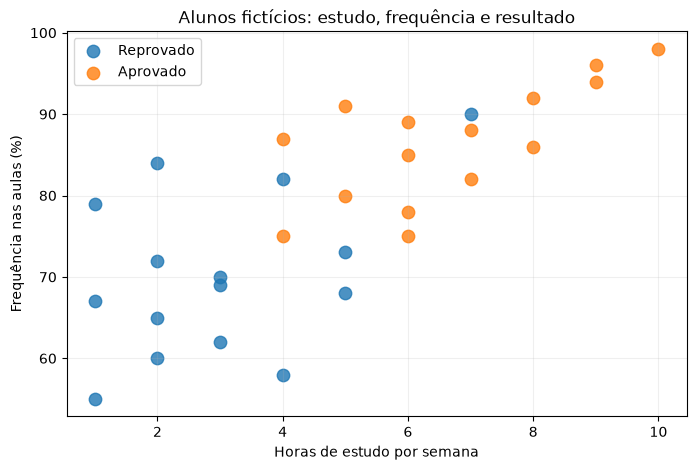

In [5]:
# Separando os alunos por classe apenas para colorir o gráfico.
reprovados = df_alunos[df_alunos["aprovado"] == 0]
aprovados = df_alunos[df_alunos["aprovado"] == 1]

plt.figure(figsize=(8, 5))

# Um ponto por aluno reprovado.
plt.scatter(
    reprovados["horas_estudo"],
    reprovados["frequencia"],
    label="Reprovado",
    s=80,
    alpha=0.8
)

# Um ponto por aluno aprovado.
plt.scatter(
    aprovados["horas_estudo"],
    aprovados["frequencia"],
    label="Aprovado",
    s=80,
    alpha=0.8
)

plt.title("Alunos fictícios: estudo, frequência e resultado")
plt.xlabel("Horas de estudo por semana")
plt.ylabel("Frequência nas aulas (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 4. Separando `X` e `y`

O modelo receberá **duas características de entrada**. O resultado de aprovação será a resposta que ele tentará aprender.

A coluna `situacao` contém apenas nomes legíveis e **não entra no modelo**.

In [8]:
# X: características usadas na previsão (duas colunas).
X = df_alunos[["horas_estudo", "frequencia"]]

# y: resposta conhecida que o algoritmo tentará aprender.
y = df_alunos["aprovado"]

print("Exemplo de X (entradas):")
print(X.head())

print("\nExemplo de y (respostas):")
print(y.head())

Exemplo de X (entradas):
   horas_estudo  frequencia
0             1          55
1             2          60
2             1          67
3             3          62
4             2          72

Exemplo de y (respostas):
0    0
1    0
2    0
3    0
4    0
Name: aprovado, dtype: int64


## 5. Dividindo treino e teste

**Por que separar?** Se avaliarmos o modelo usando os mesmos exemplos do treinamento, ele pode parecer melhor do que realmente é.

- **Treino:** exemplos que o algoritmo pode utilizar para aprender;
- **Teste:** exemplos reservados para verificar se ele consegue prever dados que não viu durante o treinamento.

Usaremos `25%` para teste. `random_state=42` deixa a divisão reproduzível. `stratify=y` procura manter proporções semelhantes de aprovados e reprovados nos dois grupos.

In [10]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.25,   # 25% dos alunos ficam separados para teste.
    random_state=42,  # Repete a mesma divisão em outras execuções.
    stratify=y         # Mantém o equilíbrio entre as duas classes.
)

print("Exemplos usados para treino:", len(X_treino))
print("Exemplos reservados para teste:", len(X_teste))
print(X_treino)
print(X_teste)

Exemplos usados para treino: 22
Exemplos reservados para teste: 8
    horas_estudo  frequencia
17             5          80
12             4          82
8              2          65
10             3          69
7              1          79
1              2          60
5              4          58
27             5          91
21             7          90
14             5          68
2              1          67
15             6          78
0              1          55
28             6          89
26             7          82
9              4          75
23             6          75
24             8          86
4              2          72
20             9          96
18             8          92
25             9          94
    horas_estudo  frequencia
3              3          62
16             7          88
29             4          87
19             6          85
13             2          84
22            10          98
11             5          73
6              3          70


## 6. Criando e treinando o KNN

O KNN compara **distâncias** entre alunos. Mas as escalas das variáveis são diferentes: horas de estudo variam aproximadamente de 1 a 10, enquanto a frequência varia de 55 a 98.

Para uma variável não dominar a distância por causa da unidade, usaremos:

1. `StandardScaler`: coloca as características em escalas comparáveis;
2. `KNeighborsClassifier`: identifica os vizinhos mais próximos.

Um `Pipeline` executa as duas etapas na ordem correta. Ao chamar `fit()` com os dados de **treino**, o padronizador aprende seus parâmetros somente nesses dados, evitando o vazamento de informação (*data leakage*) do teste.

In [23]:
import joblib
# Quantidade de vizinhos do KNN.
# EXPERIMENTE: altere 3 para 1, 5 ou 7 e execute novamente
# esta célula e as células de previsão e avaliação.
k_vizinhos = 10

# Um pipeline primeiro padroniza e depois treina o KNN.
modelo_knn = Pipeline([
    ("padronizacao", StandardScaler()),
    ("classificador", KNeighborsClassifier(n_neighbors=k_vizinhos))
])

# fit() = aprende usando X (características) E y (respostas).
modelo_knn.fit(X_treino, y_treino)

print(f"Modelo KNN treinado com {k_vizinhos} vizinhos!")


modelo_knn.predict([[5,76.9]])

joblib.dump(modelo_knn, "modelo_aprovacao_escola.pkl")

Modelo KNN treinado com 10 vizinhos!


C:\Users\PROG05\AppData\Roaming\Python\Python313\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


['modelo_aprovacao_escola.pkl']

## 7. Fazendo e conferindo previsões

Agora entregamos ao modelo **somente as entradas** dos alunos que ficaram reservados para teste. O modelo devolve `0` ou `1` para cada aluno.

Depois, comparamos a previsão com a resposta correta.

In [19]:
# predict() recebe os dados de teste sem mostrar as respostas.
previsoes = modelo_knn.predict(X_teste)

# Montamos uma tabela para facilitar a comparação.
comparacao = X_teste.copy().reset_index(drop=True)
comparacao["real"] = y_teste.reset_index(drop=True).map({
    0: "Reprovado", 1: "Aprovado"
})
comparacao["previsto"] = pd.Series(previsoes).map({
    0: "Reprovado", 1: "Aprovado"
})

# A última coluna mostra se o resultado foi igual ao esperado.
comparacao["acertou"] = comparacao["real"] == comparacao["previsto"]

comparacao

,horas_estudo,frequencia,real,previsto,acertou
0,3,62,Reprovado,Reprovado,True
1,7,88,Aprovado,Aprovado,True
2,4,87,Aprovado,Aprovado,True
3,6,85,Aprovado,Aprovado,True
4,2,84,Reprovado,Reprovado,True
5,10,98,Aprovado,Aprovado,True
6,5,73,Reprovado,Aprovado,False
7,3,70,Reprovado,Reprovado,True


## 8. Avaliando: acurácia e matriz de confusão

**Acurácia:** é a proporção de previsões corretas no conjunto de teste. Por exemplo, `0,875` significa `87,5%` de acertos.

**Matriz de confusão:** compara as classes reais com as classes previstas:

- Diagonal principal: classificações corretas;
- Fora da diagonal: erros.

> Com tão poucos dados, a métrica varia bastante dependendo de quais exemplos entram no teste. Um desempenho bom nesta atividade não comprova que o modelo funcionaria bem em uma escola de verdade.

Acurácia no teste: 87.5%


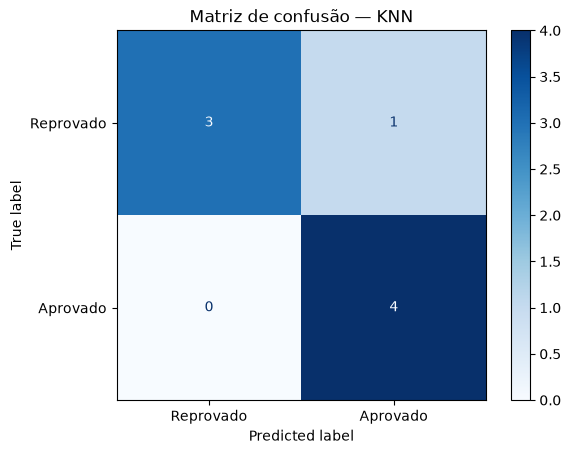

In [25]:
# Acurácia: quantidade de acertos dividida pelo total de testes.
acuracia = accuracy_score(y_teste, previsoes)
print(f"Acurácia no teste: {acuracia:.1%}")

# Desenha a matriz de confusão sem cálculos manuais.
ConfusionMatrixDisplay.from_predictions(
    y_teste,
    previsoes,
    labels=[0, 1],
    display_labels=["Reprovado", "Aprovado"],
    cmap="Blues"
)

plt.title("Matriz de confusão — KNN")
plt.show()

## 9. Testando com um aluno novo

Esse aluno **não precisa estar no DataFrame de treinamento**. Você escolhe as medidas e pede a previsão.

**Atenção:** devemos fornecer exatamente as mesmas características usadas no treino, na mesma ordem e com as mesmas unidades.

In [26]:
# EXPERIMENTE: mude os dois valores abaixo e execute novamente.
novo_aluno = pd.DataFrame({
    "horas_estudo": [5],  # Quantas horas por semana?
    "frequencia": [78]    # Qual a frequência percentual?
})

# O pipeline padroniza os números e depois aplica o KNN.
classe_prevista = modelo_knn.predict(novo_aluno)[0]

# Trocamos o número por um texto mais amigável.
nomes_classes = {0: "Reprovado", 1: "Aprovado"}

print("Dados do novo aluno:")
print(novo_aluno)
print("\nPrevisão do modelo:", nomes_classes[classe_prevista])
print("(Exemplo didático: não usar para decidir aprovação real.)")

Dados do novo aluno:
   horas_estudo  frequencia
0             5          78

Previsão do modelo: Aprovado
(Exemplo didático: não usar para decidir aprovação real.)


### Experimente — classificação (5 min)

1. Volte à célula de treinamento e troque `k_vizinhos = 3` por `1`, depois por `7`. Reexecute **treinamento, previsão e avaliação**. A acurácia mudou? Por que os vizinhos podem influenciar o resultado?
2. Mude as horas de estudo e a frequência do **novo aluno**. Teste um perfil com 2 horas/semana e 60% de frequência e outro com 9 horas/semana e 95%.
3. **Responda:** qual é a diferença entre `X` e `y`? Por que reservamos dados para teste?

> **Nota para projetos reais:** aqui mudamos o número de vizinhos para observar o comportamento do algoritmo. Para escolher um hiperparâmetro de forma rigorosa, usaríamos validação sobre os dados de treino, deixando o conjunto de teste para a avaliação final.

---
# Parte 2 — Agrupamento de clientes com KMeans (20 min)

## 10. O problema

Uma loja possui informações de clientes, mas **não informou a qual perfil cada cliente pertence**.

Para cada cliente, conhecemos:

- Quantas compras ele realiza por mês;
- Quanto gasta, em média, por compra (R$).

Queremos que o algoritmo descubra grupos de pessoas com comportamentos parecidos.

Isso é **aprendizado não supervisionado**: fornecemos apenas as características `X`, **sem uma coluna `y` com respostas corretas**.

### Como o KMeans funciona?

O KMeans procura centros de grupos (*centroides*) e associa cada cliente ao centro mais próximo. Antes de treinar, precisamos informar quantos grupos (`n_clusters`) queremos procurar.

> **Importante:** os números `0`, `1`, `2` usados nos grupos são identificadores arbitrários. Não representam uma ordem de qualidade ou importância.

## 11. Criando o DataFrame de clientes

Estes 18 clientes são fictícios. Propositalmente, criamos hábitos de compras diferentes para enxergar melhor o efeito do clustering.

Observe que **não existe uma coluna contendo o grupo correto**.

In [27]:
# Base pequena com 18 clientes e apenas duas características.
df_clientes = pd.DataFrame({
    "cliente": [
        "C01", "C02", "C03", "C04", "C05", "C06",
        "C07", "C08", "C09", "C10", "C11", "C12",
        "C13", "C14", "C15", "C16", "C17", "C18"
    ],
    "compras_mes": [
        1, 2, 1, 3, 2, 1,
        4, 5, 4, 6, 5, 6,
        8, 9, 7, 10, 8, 9
    ],
    "gasto_medio_reais": [
        45, 55, 60, 50, 70, 80,
        160, 190, 240, 210, 180, 260,
        390, 450, 360, 500, 420, 480
    ]
})

# Exibe todos os clientes (é uma tabela pequena).
df_clientes

,cliente,compras_mes,gasto_medio_reais
0,C01,1,45
1,C02,2,55
2,C03,1,60
3,C04,3,50
4,C05,2,70
5,C06,1,80
6,C07,4,160
7,C08,5,190
8,C09,4,240
9,C10,6,210


## 12. Observando os clientes antes do algoritmo

Este gráfico não possui rótulos de grupos: representa apenas os dados **antes** do clustering.

**Pergunta:** você consegue perceber conjuntos de pontos visualmente próximos?

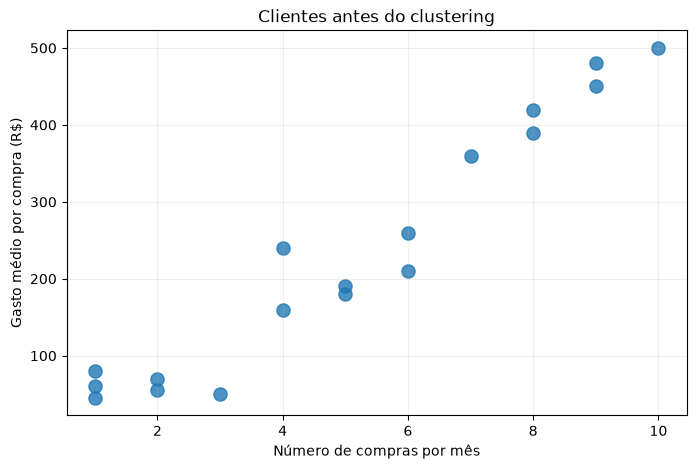

In [28]:
plt.figure(figsize=(8, 5))

# Ainda não usamos nenhuma classe ou grupo.
plt.scatter(
    df_clientes["compras_mes"],
    df_clientes["gasto_medio_reais"],
    s=90,
    alpha=0.8
)

plt.title("Clientes antes do clustering")
plt.xlabel("Número de compras por mês")
plt.ylabel("Gasto médio por compra (R$)")
plt.grid(alpha=0.2)
plt.show()

## 13. Preparando as características

Repare que **compras por mês** assume números pequenos, mas **gasto médio em reais** tem valores muito maiores. O KMeans também utiliza distâncias; portanto, vamos padronizar as duas características.

A coluna `cliente` é apenas um identificador e **não deve entrar no cálculo das distâncias**.

Aqui usaremos `StandardScaler` diretamente, sem Pipeline, para deixar visível cada etapa.

In [29]:
# X_clientes contém apenas as variáveis numéricas relevantes.
X_clientes = df_clientes[["compras_mes", "gasto_medio_reais"]]

# Cria um objeto capaz de padronizar cada coluna.
escalador_clientes = StandardScaler()

# Aprende a média/desvio de cada coluna e transforma os valores.
X_clientes_padronizado = escalador_clientes.fit_transform(X_clientes)

# Mostra apenas os três primeiros registros depois da transformação.
print("Três primeiros clientes com dados padronizados:")
print(X_clientes_padronizado[:3])

Três primeiros clientes com dados padronizados:
[[-1.3912967  -1.19531554]
 [-1.04823724 -1.13184746]
 [-1.3912967  -1.10011341]]


## 14. Encontrando grupos com KMeans

Agora vem a principal diferença em relação ao KNN:

- **Classificação:** `fit(X_treino, y_treino)` — conhece as respostas no treino;
- **Clustering:** `fit_predict(X)` — **não recebe `y`** e cria grupos por semelhança.

Neste exemplo introdutório usaremos a base toda para encontrar os grupos. Não faremos treino/teste da mesma maneira que na classificação, porque não temos rótulos corretos para comparar com as previsões.

In [30]:
# EXPERIMENTE: altere para 2 ou 4 depois de observar a versão inicial.
numero_grupos = 3

# Cria o modelo KMeans que procurará 'numero_grupos' grupos.
modelo_kmeans = KMeans(
    n_clusters=numero_grupos,
    random_state=42,  # Permite reproduzir o exemplo.
    n_init=10         # Faz várias inicializações e escolhe a melhor.
)

# Executa o agrupamento usando apenas as características (sem y).
grupos_encontrados = modelo_kmeans.fit_predict(X_clientes_padronizado)

# Adiciona uma coluna ao DataFrame com o grupo atribuído a cada cliente.
df_clientes["grupo"] = grupos_encontrados

# Exibe a tabela com os grupos recém-criados.
df_clientes

,cliente,compras_mes,gasto_medio_reais,grupo
0,C01,1,45,2
1,C02,2,55,2
2,C03,1,60,2
3,C04,3,50,2
4,C05,2,70,2
5,C06,1,80,2
6,C07,4,160,0
7,C08,5,190,0
8,C09,4,240,0
9,C10,6,210,0


## 15. Visualizando os clusters

Agora o gráfico usa cores para diferenciar os **grupos encontrados pelo algoritmo**.

O símbolo `X` marca o centro aproximado de cada grupo, chamado **centroide**. Como o modelo trabalhou com números padronizados, convertemos os centros novamente para as unidades originais apenas para desenhar o gráfico.

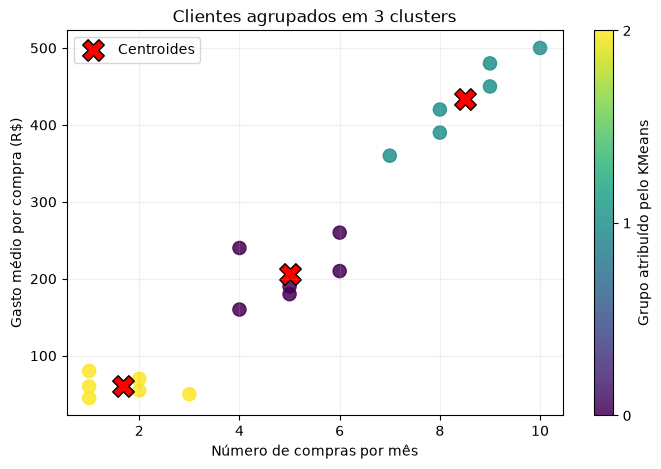

In [31]:
# Os centroides estavam padronizados; aqui voltam a compras/mês e R$.
centros_originais = escalador_clientes.inverse_transform(
    modelo_kmeans.cluster_centers_
)

plt.figure(figsize=(8, 5))

# c= define a cor do ponto a partir do número de seu grupo.
pontos = plt.scatter(
    df_clientes["compras_mes"],
    df_clientes["gasto_medio_reais"],
    c=df_clientes["grupo"],
    cmap="viridis",
    s=90,
    alpha=0.85
)

# Marca os centroides com X grande.
plt.scatter(
    centros_originais[:, 0],
    centros_originais[:, 1],
    marker="X",
    s=240,
    c="red",
    edgecolors="black",
    label="Centroides"
)

plt.colorbar(
    pontos,
    ticks=sorted(df_clientes["grupo"].unique()),
    label="Grupo atribuído pelo KMeans"
)
plt.title(f"Clientes agrupados em {numero_grupos} clusters")
plt.xlabel("Número de compras por mês")
plt.ylabel("Gasto médio por compra (R$)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 16. Interpretando os grupos

O algoritmo encontrou grupos, **mas não escolheu nomes de negócio** como “econômico” ou “frequente”. Essa interpretação é feita por uma pessoa.

Para ajudar na análise, vamos descobrir:

1. A quantidade de clientes em cada grupo;
2. O valor médio das características de cada grupo.

Lembre-se: o número de cada grupo pode mudar em outra execução ou quando alteramos os dados.

In [32]:
# Quantos clientes cada grupo recebeu?
print("Clientes em cada grupo:")
print(df_clientes["grupo"].value_counts().sort_index())

# Calcula médias das duas características dentro de cada grupo.
# As médias ajudam a DESCREVER os grupos após o clustering.
resumo_grupos = df_clientes.groupby("grupo")[[
    "compras_mes", "gasto_medio_reais"
]].mean().round(1)

print("\nMédia das características por grupo:")
print(resumo_grupos)

Clientes em cada grupo:
grupo
0    6
1    6
2    6
Name: count, dtype: int64

Média das características por grupo:
       compras_mes  gasto_medio_reais
grupo                                
0              5.0              206.7
1              8.5              433.3
2              1.7               60.0


### Experimente — clustering (5 min)

1. Na célula do KMeans, troque `numero_grupos = 3` por `2`. Reexecute o treino, o gráfico e o resumo. Quais clientes passaram a dividir o mesmo grupo?
2. Repita com `numero_grupos = 4`. O que mudou? Mais grupos significa necessariamente uma segmentação melhor?
3. Com base nas **médias**, invente um nome para cada grupo, como “compras ocasionais” ou “compras frequentes”. **Não presuma que o grupo 0 será sempre o mesmo perfil.**

**Desafio extra (se sobrar tempo):** altere o gasto médio do cliente `C01` de `45` para `200` no DataFrame original e execute novamente as células de preparação e clustering. Observe como a posição do cliente e o agrupamento podem mudar.

> Dica: o KMeans não tem uma “acurácia” equivalente à classificação neste conjunto sem rótulos. Aqui, avaliamos visualmente os grupos e se eles ajudam a entender o problema.

---
# Revisão final (5 min)

| Pergunta | Classificação (KNN) | Clustering (KMeans) |
|---|---|---|
| Tipo de aprendizado | Supervisionado | Não supervisionado |
| Recebe respostas conhecidas (`y`)? | Sim, no treino | Não |
| Principal objetivo | Prever a categoria de um novo caso | Encontrar grupos semelhantes |
| Exemplo da aula | Prever aprovado/reprovado | Agrupar hábitos de compra |
| Funções utilizadas | `fit(X, y)` e `predict(X)` | `fit_predict(X)` |
| Como analisar o resultado? | Acurácia e matriz de confusão | Gráficos e perfil médio dos grupos |

## Verificação de aprendizagem

Responda com suas próprias palavras:

1. **O que diferencia aprendizado supervisionado de não supervisionado?**
R:Acho que o supervisionado te da um pouco menos de liberdade de expressar sua opnião doque o não supervisionado

2. **Qual a função de `X` e de `y` na classificação?**
3. **Por que não é adequado avaliar um classificador somente com os dados de treino?**
4. **Por que padronizamos os valores antes de usar KNN e KMeans?**
5. **No KMeans, quem interpreta o significado dos grupos?**

### O que você aprendeu

Você criou duas tabelas com `pd.DataFrame`, treinou um classificador com KNN, testou previsões, analisou uma matriz de confusão e descobriu grupos de clientes com KMeans. Essas mesmas ideias servem como ponto de partida para projetos de Machine Learning maiores.

**Próximo passo sugerido:** salvar o classificador com `joblib` e conectá-lo a uma interface criada em Streamlit, simulando a utilização de um modelo treinado em uma aplicação web.